In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# -------------------------------
# 1. Load dataset (MNIST digits)
# -------------------------------
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data", train=True, transform=transform, download=True
)
test_dataset = torchvision.datasets.MNIST(
    root="./data", train=False, transform=transform, download=True
)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

# -------------------------------
# 2. Define Logistic Regression model
# -------------------------------
class LogisticRegression(nn.Module):
    def __init__(self, input_size, num_classes):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(input_size, num_classes)  # single linear layer

    def forward(self, x):
        x = x.view(-1, 28*28)   # flatten 28x28 image -> 784 vector
        out = self.linear(x)    # linear transformation
        return out              # logits (raw scores)

input_size = 28*28
num_classes = 10
model = LogisticRegression(input_size, num_classes)

# -------------------------------
# 3. Loss function & optimizer
# -------------------------------
criterion = nn.CrossEntropyLoss()       # for multi-class classification
optimizer = optim.SGD(model.parameters(), lr=0.1)

# -------------------------------
# 4. Training loop
# -------------------------------
epochs = 5
for epoch in range(epochs):
    for images, labels in train_loader:
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass & update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# -------------------------------
# 5. Evaluate on test dataset
# -------------------------------
correct = 0
total = 0
with torch.no_grad():  # no gradients needed for evaluation
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)   # pick class with highest score
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy: {100 * correct / total:.2f}%")


100%|██████████| 9.91M/9.91M [00:26<00:00, 375kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 110kB/s]
100%|██████████| 1.65M/1.65M [00:03<00:00, 458kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.79MB/s]


Epoch [1/5], Loss: 0.3290
Epoch [2/5], Loss: 0.3119
Epoch [3/5], Loss: 0.1748
Epoch [4/5], Loss: 0.2694
Epoch [5/5], Loss: 0.1288
Test Accuracy: 92.13%


Epoch [1/5], Loss: 0.1981
Epoch [2/5], Loss: 0.2807
Epoch [3/5], Loss: 0.2502
Epoch [4/5], Loss: 0.2146
Epoch [5/5], Loss: 0.1613


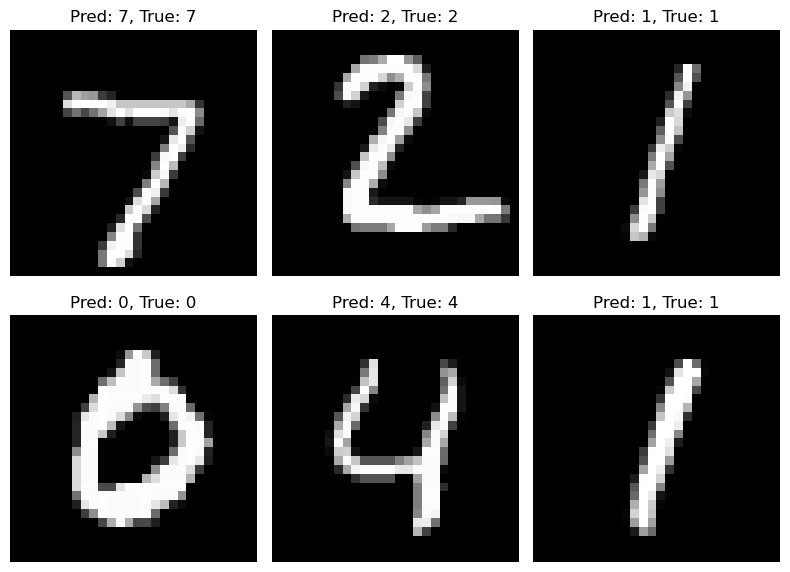

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# -------------------------------
# 1. Load dataset (MNIST)
# -------------------------------
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data", train=True, transform=transform, download=True
)
test_dataset = torchvision.datasets.MNIST(
    root="./data", train=False, transform=transform, download=True
)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

# -------------------------------
# 2. Define Logistic Regression model
# -------------------------------
class LogisticRegression(nn.Module):
    def __init__(self, input_size, num_classes):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(input_size, num_classes)

    def forward(self, x):
        x = x.view(-1, 28*28)   # flatten image
        return self.linear(x)

input_size = 28*28
num_classes = 10
model = LogisticRegression(input_size, num_classes)

# -------------------------------
# 3. Loss function & optimizer
# -------------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

# -------------------------------
# 4. Training loop
# -------------------------------
epochs = 5
for epoch in range(epochs):
    for images, labels in train_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# -------------------------------
# 5. Evaluate & visualize predictions
# -------------------------------
# Get some test images
examples = iter(test_loader)
images, labels = next(examples)

# Predict
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

# Show first 6 images with predictions
fig, axes = plt.subplots(2, 3, figsize=(8, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Pred: {predicted[i].item()}, True: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()
